In [12]:
import sys,os
sys.path.append('../../')
import matplotlib.pyplot as plt
import numpy as np
from utils import makefolder

eps = 1E-7
rcpsize = 14
plt.rcParams['xtick.labelsize']= rcpsize
plt.rcParams['ytick.labelsize']=rcpsize
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = rcpsize
plt.rcParams.update({'figure.autolayout': True})
#colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['ggplot']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8-dark-palette']['axes.prop_cycle'].by_key()['color']
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)
# print(plt.rcParams.keys())
#np.set_printoptions(precision=None)
markers = ['*','p','o','h','^']
_linestyles = ['-','--','dotted']
plot_id = 0
sys.path.append(os.path.expanduser('~/syn-sem'))
from modelpaths import get_model_depths
depths = get_model_depths()


layer_ids=array([ 0, 24, 30, 36, 42, 48, 54, 60])


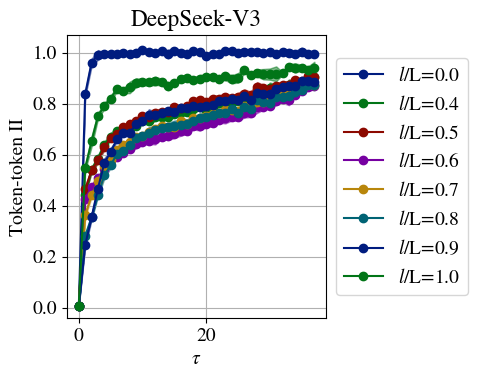

In [13]:
models = [
          # 'bert',
          'deepseek',
          # 'llama',
          ]
model_depth_keys = {
          'deepseek': 'deepseek',
          # 'llama': 'llama8b',
          # 'bert': 'bert',
          }

def get_model_depth(model_name):
  return depths[model_depth_keys.get(model_name, model_name)]
languages = [
            # 'english',
            # 'spanish',
            # 'german',
            # 'hungarian',
            'italian',
            ]
n_files = 400

mask = 2
min_token_lengths = [40]
k = 10
Nbits = 0
seed_list = np.arange(5,dtype=int) 
n_tokens = 1
take_last = 1
batch_shuffle = 0

figsfolder = f'results/figs/'
os.makedirs(figsfolder,exist_ok=True)
output_datafolder = f'{figsfolder}data/'
os.makedirs(output_datafolder,exist_ok=True)

fig,ax = plt.subplots(1,1,
                      figsize=(5,4),
                      # constrained_layout=True,
                      )
for min_token_length_id,min_token_length in enumerate(min_token_lengths):
  n_loaded_tokens = min_token_length - mask
  for model_id,model in enumerate(models):
    if model == 'deepseek': relative_depths = np.array([0.001,.4,.5,0.6, 0.7,.8,.9,0.999])
    if model == 'llama': relative_depths = np.array([.001,.7,.999])
    if model == 'bert': relative_depths = np.array([.001,.5,.999])
    layer_ids = (relative_depths * get_model_depth(model)).astype(int)
    print(f'{layer_ids=}')
    for r_id,r in enumerate(relative_depths):
      for language_id, language in enumerate(languages):
          IIs = np.zeros(shape=(len(seed_list),2,get_model_depth(model),n_loaded_tokens))
          for seed_id,seed in enumerate(seed_list):
            II_folder = makefolder(base=f'./results/santiago/',
                                   subtract_mean=0,
                                   batch_shuffle=batch_shuffle,
                                      take_last=take_last,
                                      modelA=model,
                                      modelB=model,
                                      n_files=n_files,
                                      min_token_length=min_token_length,
                                      languageA=language,
                                      mask=mask,
                                      k=k,
                                      Nbits=Nbits,
                                      seed=seed,
                                      )
            IIs[seed_id,0] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_AB.npy')
            IIs[seed_id,1] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_BA.npy')
          x = np.arange(0,n_loaded_tokens)
          mu_ab = IIs[:,0,layer_ids[r_id],:].mean(axis=0)
          std_ab = IIs[:,0,layer_ids[r_id],:].std(axis=0)
          ax.plot(x,
                    mu_ab,
                    linestyle=_linestyles[0],
                    label=f'$l$/L={round(relative_depths[r_id],1)}',
                    marker='o',
                    color=colors[r_id%len(colors)],)
          ax.fill_between(x,mu_ab-std_ab,mu_ab+std_ab,alpha=.5,color=colors[r_id%len(colors)])
          mu_ba = IIs[:,1,layer_ids[r_id],:].mean(axis=0)
          std_ba = IIs[:,1,layer_ids[r_id],:].std(axis=0)
          # ax.plot(x,
          #           mu_ba,
          #           linestyle=_linestyles[1],
          #           label=f'{model}[{language}] l/L={round(relative_depths[r_id],1)} reciprocal',
          #           marker='o',
          #           color=colors[r_id%len(colors)],
          #           mfc='none',
          #           )
          # ax.fill_between(x,mu_ba-std_ba,mu_ba+std_ba,alpha=.5,color=colors[r_id%len(colors)])
          # np.savetxt(output_datafolder + f'{model}_{language}_layer{layer_ids[r_id]+1}_{min_token_length}_from_last.txt',
          #            IIs[:,0,layer_ids[r_id],:].mean(axis=0))
          # np.savetxt(output_datafolder + f'{model}_{language}_layer{layer_ids[r_id]+1}_{min_token_length}_to_last.txt',
          #            IIs[:,1,layer_ids[r_id],:].mean(axis=0))

# ax.set_xscale('log')
# ax.set_yscale('log')
ax.grid()
ax.set_xlabel(r'$\tau$')
ax.set_ylabel('Token-token II')
# ax.set_ylim(-0.01,1.01)
if model == 'deepseek': 
  _modelname = 'DeepSeek-V3'
ax.set_title(_modelname)

box = ax.get_position()
ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
# ax.legend()
fig.savefig(f'{figsfolder}_{model}_{layer_ids}_future-past-II.pdf',bbox_inches='tight')

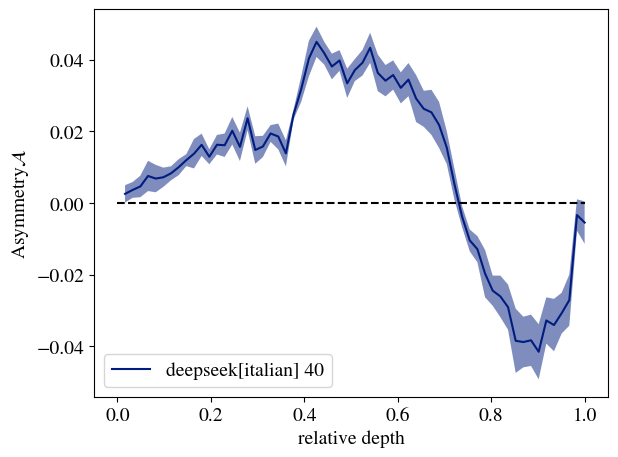

In [14]:
fig,ax = plt.subplots(1)

min_token_lengths = [40]
seed_list = np.arange(5,dtype=int)
for model_id,model in enumerate(models):
  for min_token_length_id,min_token_length in enumerate(min_token_lengths):
    n_loaded_tokens = min_token_length - mask
    for language_pair, language in enumerate(languages):
        IIs = np.zeros(shape=(len(seed_list),2,get_model_depth(model),n_loaded_tokens))
        for seed_id,seed in enumerate(seed_list):
          II_folder = makefolder(base=f'./results/santiago/',
                                 subtract_mean=0,
                                  batch_shuffle=batch_shuffle,
                                      take_last=take_last,
                                      modelA=model,
                                      modelB=model,
                                      n_files=n_files,
                                      min_token_length=min_token_length,
                                      languageA=language,
                                      mask=mask,
                                      k=k,
                                      Nbits=Nbits,
                                      seed=seed,
                                    )
          IIs[seed_id,0] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_AB.npy')
          IIs[seed_id,1] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_BA.npy')
        A = (IIs[:,0,:,:]- IIs[:,1,:,:]).mean(axis=-1)
        mu = A.mean(axis=0)
        std = A.std(axis=0)
        x = np.arange(1,get_model_depth(model)+1)/get_model_depth(model)
        ax.plot(x,
                  mu,
                  label=f'{model}[{language}] {min_token_length}',
                  )
        ax.fill_between(x,mu-std,mu+std,alpha=.5)
        # np.savetxt(f'{output_datafolder}asymmetry_layers_{model}_{language}_{min_token_length}.txt',
        # np.array([np.arange(1,get_model_depth(model)+1),A]).T)


ax.set_ylabel('Asymmetry' + r'$\mathcal{A}$')  
ax.set_xlabel('relative depth')
# ax.set_title(f'{min_token_length=}')

ax.hlines(0,0,1,color='black',linestyles='dashed')
ax.legend()
plt.show()

layer_ids=array([ 0,  6, 12, 18, 24, 30, 36, 42, 48, 54, 60])


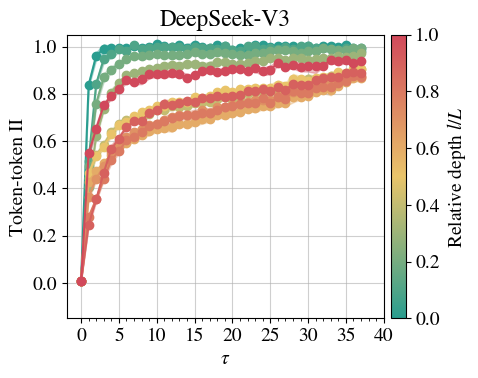

In [15]:
# Continuous 3-anchor depth colormap + colorbar remake of the first plot
fig,ax = plt.subplots(1,1,
                      figsize=(5,4),
                      )
for min_token_length_id,min_token_length in enumerate(min_token_lengths):
  n_loaded_tokens = min_token_length - mask
  for model_id,model in enumerate(models):
    if model == 'deepseek': relative_depths = np.array([0.001,.2,.4,0.6,.8,0.999])
    if model == 'deepseek': relative_depths = np.array([0.001,1/3.,.5, 2/3.,0.999])
    if model == 'deepseek': relative_depths = np.array([0.001,1/10,.2,.3,.4,.5,.6,.7,.8,.9,0.999])
    if model == 'llama': relative_depths = np.array([.001,.7,.999])
    if model == 'bert': relative_depths = np.array([.001,.5,.999])
    layer_ids = (relative_depths * get_model_depth(model)).astype(int)
    # Continuous map that interpolates through 3 anchor colors across relative depth.
    depth_cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
        'depth3',
        ['#2A9D8F', '#E9C46A', '#D1495B'],
        N=256,
    )
    depth_norm = plt.Normalize(vmin=0.0, vmax=1.0)
    depth_colors = depth_cmap(depth_norm(relative_depths))
    print(f'{layer_ids=}')
    for r_id,r in enumerate(relative_depths):
      for language_id, language in enumerate(languages):
          IIs = np.zeros(shape=(len(seed_list),2,get_model_depth(model),n_loaded_tokens))
          for seed_id,seed in enumerate(seed_list):
            II_folder = makefolder(base=f'./results/santiago/',
                                   subtract_mean=0,
                                   batch_shuffle=batch_shuffle,
                                      take_last=take_last,
                                      modelA=model,
                                      modelB=model,
                                      n_files=n_files,
                                      min_token_length=min_token_length,
                                      languageA=language,
                                      mask=mask,
                                      k=k,
                                      Nbits=Nbits,
                                      seed=seed,
                                      )
            IIs[seed_id,0] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_AB.npy')
            IIs[seed_id,1] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_BA.npy')
          x = np.arange(0,n_loaded_tokens)
          mu_ab = IIs[:,0,layer_ids[r_id],:].mean(axis=0)
          std_ab = IIs[:,0,layer_ids[r_id],:].std(axis=0)
          ax.plot(x,
                    mu_ab,
                    linestyle=_linestyles[0],
                    label=f'$l$/L={round(relative_depths[r_id],1)}',
                    marker='o',
                    color=depth_colors[r_id],)
          ax.fill_between(x,mu_ab-std_ab,mu_ab+std_ab,alpha=.35,color=depth_colors[r_id])

ax.set_xlabel(r'$\tau$')
ax.set_ylabel('Token-token II')
# ax.set_xlim(0,40)
ax.set_xticks(np.arange(0,41,5))
ax.set_xticks(np.arange(0,41,1), minor=True)
ax.grid(which='major', alpha=0.6)
# ax.grid(which='minor', alpha=0.2)
ax.set_ylim(-0.15,1.05)
if model == 'deepseek':
  _modelname = 'DeepSeek-V3'
ax.set_title(_modelname)

sm = plt.cm.ScalarMappable(cmap=depth_cmap, norm=depth_norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label(r'Relative depth $l/L$')
cbar_ticks = np.round(np.linspace(0.0, 1.0, 6), 2)
cbar.set_ticks(cbar_ticks)
cbar.set_ticklabels([f'{t:.1f}' for t in cbar_ticks])
fig.savefig(fname=f'results/{model}_token-token-II.pdf')
plt.show()

/tmp/ipykernel_1508095/3988303169.py:67: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.savefig('results/figs/_deepseek_english_vs_italian_correlations.pdf', bbox_inches='tight')
/home/acevedo/venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


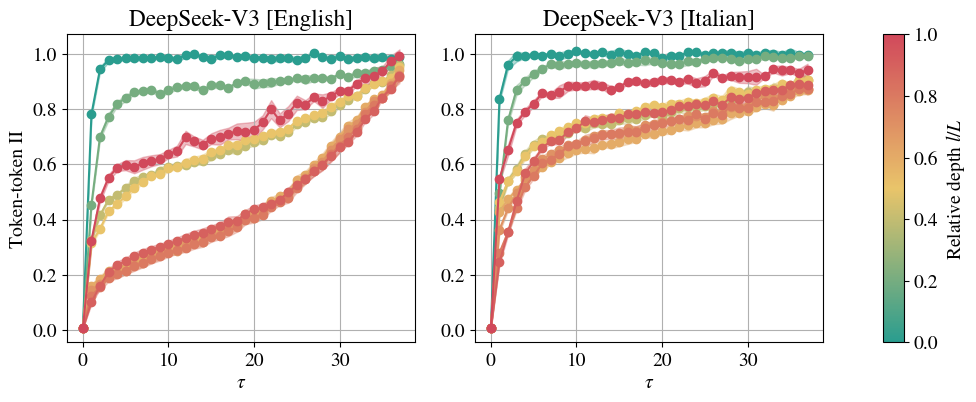

In [16]:
# Side-by-side DeepSeek correlations in English and Italian
compare_languages = ['english', 'italian']
model = 'deepseek'
model_depth = get_model_depth(model)
relative_depths = np.array([0.001,.2, .4, .5, 0.6, 0.7, .8, .9, 0.999])
layer_ids = (relative_depths * model_depth).astype(int)
min_token_length = min_token_lengths[0]
n_loaded_tokens = min_token_length - mask

depth_cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    'depth3_compare',
    ['#2A9D8F', '#E9C46A', '#D1495B'],
    N=256,
)
depth_norm = plt.Normalize(vmin=0.0, vmax=1.0)
depth_colors = depth_cmap(depth_norm(relative_depths))

fig = plt.figure(figsize=(10.8, 4))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.06], wspace=0.25)
ax0 = fig.add_subplot(gs[0, 0])
ax1 = fig.add_subplot(gs[0, 1], sharey=ax0)
axes = [ax0, ax1]
cax = fig.add_subplot(gs[0, 2])

for ax, language in zip(axes, compare_languages):
  IIs = np.zeros(shape=(len(seed_list), 2, model_depth, n_loaded_tokens))
  for seed_id, seed in enumerate(seed_list):
    II_folder = makefolder(base='./results/santiago/',
                           subtract_mean=0,
                           batch_shuffle=batch_shuffle,
                           take_last=take_last,
                           modelA=model,
                           modelB=model,
                           n_files=n_files,
                           min_token_length=min_token_length,
                           languageA=language,
                           mask=mask,
                           k=k,
                           Nbits=Nbits,
                           seed=seed)
    IIs[seed_id,0] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_0_AB.npy')

  x = np.arange(0, n_loaded_tokens)
  for r_id, r in enumerate(relative_depths):
    mu_ab = IIs[:,0,layer_ids[r_id],:].mean(axis=0)
    std_ab = IIs[:,0,layer_ids[r_id],:].std(axis=0)
    ax.plot(x,
            mu_ab,
            linestyle=_linestyles[0],
            marker='o',
            color=depth_colors[r_id])
    ax.fill_between(x, mu_ab - std_ab, mu_ab + std_ab, alpha=.35, color=depth_colors[r_id])

  ax.grid()
  ax.set_xlabel(r'$\tau$')
  ax.set_title(f'DeepSeek-V3 [{language.title()}]')

axes[0].set_ylabel('Token-token II')
sm = plt.cm.ScalarMappable(cmap=depth_cmap, norm=depth_norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label(r'Relative depth $l/L$')
cbar_ticks = np.round(np.linspace(0.0, 1.0, 6), 2)
cbar.set_ticks(cbar_ticks)
cbar.set_ticklabels([f'{t:.1f}' for t in cbar_ticks])

fig.savefig('results/figs/_deepseek_english_vs_italian_correlations.pdf', bbox_inches='tight')
plt.show()
